# Self-Supervised Pre-Training on PatchCamelyon (PCam): RotNet vs. Mini-SimCLR

An exploratory comparison of rotation-prediction pre-training (RotNet, inspired by Kupferschmidt et al., MIDL 2021) and a small-scale contrastive baseline (Mini-SimCLR) on 4,000 unlabeled PCam patches in a low-label regime ($N_c = 100$ per class).

This notebook evaluates **six ResNet-34 initializations** under **two downstream protocols**:
1. **Baselines:** Randomly initialized ResNet-34 (BatchNorm-calibrated on unlabeled patches) and ImageNet-pretrained ResNet-34.
2. **RotNet & Augmentation Ablation:** RotNet (no extra augmentation) and RotNet (+ crop & color jitter), plus held-out 4-way rotation accuracy on unseen test patches.
3. **Mini-SimCLR & Rotation Ablation:** Mini-SimCLR (with discrete rotations/flips) and Mini-SimCLR (without rotations/flips).

Downstream evaluation compares:
- **Protocol 1 (Frozen Linear Probe):** `StandardScaler` + 5-fold CV `LogisticRegressionCV` across 10 draws of $N_c = 100$.
- **Protocol 2 (End-to-End Fine-Tuning):** Unfrozen ResNet-34 trained for 100 epochs (Adam, `lr=1e-3`, `weight_decay=1e-3`, batch size 64) across 3 draws of $N_c = 100$.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from data_loader import (
    IMAGENET_MEAN, IMAGENET_STD, SimCLRAugmentation, load_pcam_subsets, set_seed
)
from models import BackboneWrapper
from train_ssl import (
    calibrate_batchnorm, evaluate_heldout_rotation_accuracy, train_rotnet, train_simclr
)
from evaluate import (
    evaluate_finetune_models, evaluate_linear_probe_models,
    plot_mean_roc_curves, print_paired_differences
)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Data Loading & Per-Channel Statistics
Subsets are streamed with shuffling (`buffer_size=10,000`) from `1aurent/PatchCamelyon` official `train` and `test` splits. Per-channel RGB mean and standard deviation are computed strictly on the 4,000 unlabeled training patches.

In [2]:
SEEDS = (42, 101, 202, 303, 404, 505, 606, 707, 808, 909)
FINETUNE_SEEDS = (42, 101, 202)

data = load_pcam_subsets(
    num_unlabeled=4000,
    nc_labeled=100,
    num_test=5000,
    seeds=SEEDS,
    stream_seed=42,
)

unlabeled_images = data["unlabeled"]
pcam_mean, pcam_std = data["mean"], data["std"]
labeled_seeds = data["labeled_seeds"]
test_images, test_labels = data["test"]

print(f"Loaded: {len(unlabeled_images)} unlabeled, {len(SEEDS)} labeled draws (Nc=100), {len(test_images)} test patches.")

Streaming shuffled subsets from Hugging Face ('1aurent/PatchCamelyon')...


Sampling 4000 unlabeled patches from shuffled train split...
  Unlabeled pool class balance (logged before stripping labels): 48.3% positive
  Computed unlabeled RGB mean=[0.6974, 0.5361, 0.6887], std=[0.2373, 0.2789, 0.2151]
Sampling 5000 balanced holdout test patches from shuffled official test split...
Loaded: 4000 unlabeled, 10 labeled draws (Nc=100), 5000 test patches.


## 2. Augmentation Inspection

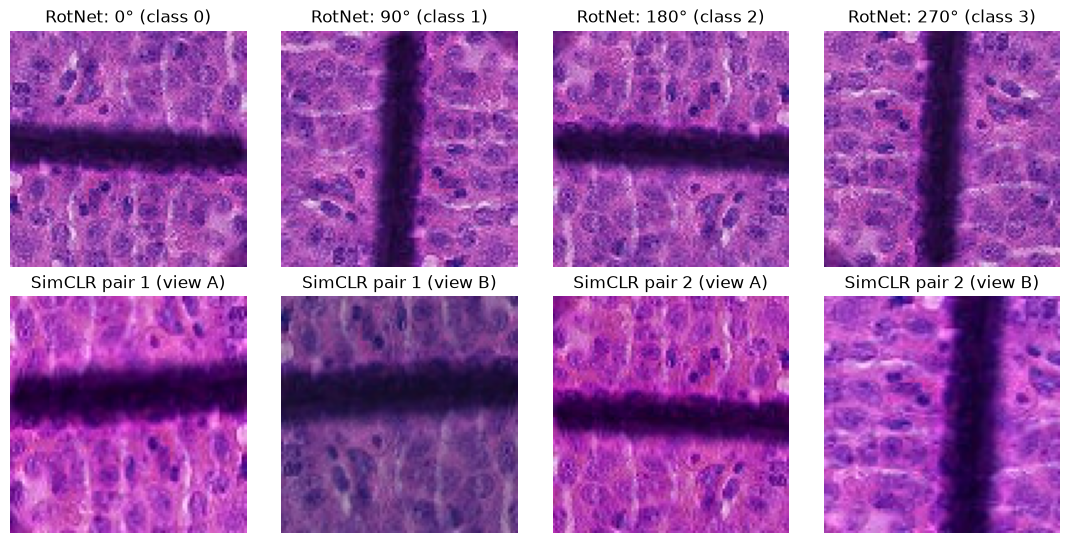

In [3]:
sample_img = unlabeled_images[0]
fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))

for i, angle in enumerate([0, 90, 180, 270]):
    axes[0, i].imshow(sample_img.rotate(angle))
    axes[0, i].set_title(f"RotNet: {angle}° (class {i})")
    axes[0, i].axis("off")

simclr_aug = SimCLRAugmentation(mean=pcam_mean, std=pcam_std, use_rotation=True)
m_arr = np.array(pcam_mean).reshape(3, 1, 1)
s_arr = np.array(pcam_std).reshape(3, 1, 1)

for i in range(2):
    v1, v2 = simclr_aug(sample_img)
    d1 = np.clip((v1.numpy() * s_arr + m_arr).transpose(1, 2, 0), 0, 1)
    d2 = np.clip((v2.numpy() * s_arr + m_arr).transpose(1, 2, 0), 0, 1)
    axes[1, 2 * i].imshow(d1)
    axes[1, 2 * i].set_title(f"SimCLR pair {i+1} (view A)")
    axes[1, 2 * i].axis("off")
    axes[1, 2 * i + 1].imshow(d2)
    axes[1, 2 * i + 1].set_title(f"SimCLR pair {i+1} (view B)")
    axes[1, 2 * i + 1].axis("off")

plt.tight_layout()
plt.show()

## 3. Part 1 — RotNet Pre-Training & Held-Out Rotation Diagnostic
We train two RotNet variants for 30 epochs (`eff_batch=256`, `lr=1e-3`, `weight_decay=1e-3`):
- `RotNet (no aug)`: raw patches + 4-way rotation.
- `RotNet (+ crop/jitter)`: crop + color jitter matching SimCLR before 4-way rotation.

We then measure 4-way rotation accuracy on unseen test patches (chance = 25.0%) to test whether low training loss reflects generalizable directional cues or memorization.

In [4]:
rotnet_raw, rot_raw_losses = train_rotnet(
    unlabeled_images, pcam_mean, pcam_std, epochs=30, batch_size=64, use_aug=False, seed=42, device=device
)
rotnet_aug, rot_aug_losses = train_rotnet(
    unlabeled_images, pcam_mean, pcam_std, epochs=30, batch_size=64, use_aug=True, seed=42, device=device
)

rot_acc_raw = evaluate_heldout_rotation_accuracy(rotnet_raw, test_images, pcam_mean, pcam_std, device)
rot_acc_aug = evaluate_heldout_rotation_accuracy(rotnet_aug, test_images, pcam_mean, pcam_std, device)
print(f"\nHeld-out 4-way rotation accuracy (chance = 25.0%):")
print(f"  RotNet (no aug):       {rot_acc_raw:.2f}%")
print(f"  RotNet (+ crop/jitter): {rot_acc_aug:.2f}%")


Pre-training RotNet (no aug) (30 epochs, 4000 patches, eff_batch=256)...


  Epoch 01/30 | Loss: 1.4126


  Epoch 10/30 | Loss: 0.8473


  Epoch 20/30 | Loss: 0.6081


  Epoch 30/30 | Loss: 0.3958

Pre-training RotNet (+ crop/jitter) (30 epochs, 4000 patches, eff_batch=256)...


  Epoch 01/30 | Loss: 1.4335


  Epoch 10/30 | Loss: 1.3086


  Epoch 20/30 | Loss: 1.1986


  Epoch 30/30 | Loss: 1.0434



Held-out 4-way rotation accuracy (chance = 25.0%):
  RotNet (no aug):       36.73%
  RotNet (+ crop/jitter): 40.87%


## 4. Part 2 — Mini-SimCLR Pre-Training & Rotation Ablation
We train two Mini-SimCLR variants for 30 epochs (`eff_batch=256`, `lr=1e-3`, `weight_decay=1e-3`, `tau=0.5`):
- `SimCLR (+ rot/flip)`: crop + color jitter + discrete 90° rotations & flips.
- `SimCLR (no rot/flip)`: crop + color jitter only (ablation isolating rotation/flip invariance).


Pre-training SimCLR (+ rot/flip) (30 epochs, 4000 patches, eff_batch=256)...

  Epoch 01/30 | NT-Xent Loss: 4.4984


  Epoch 10/30 | NT-Xent Loss: 3.9393


  Epoch 20/30 | NT-Xent Loss: 3.8828


  Epoch 30/30 | NT-Xent Loss: 3.8406

Pre-training SimCLR (no rot/flip) (30 epochs, 4000 patches, eff_batch=256)...


  Epoch 01/30 | NT-Xent Loss: 4.4542


  Epoch 10/30 | NT-Xent Loss: 3.8792


  Epoch 20/30 | NT-Xent Loss: 3.8397


  Epoch 30/30 | NT-Xent Loss: 3.8016


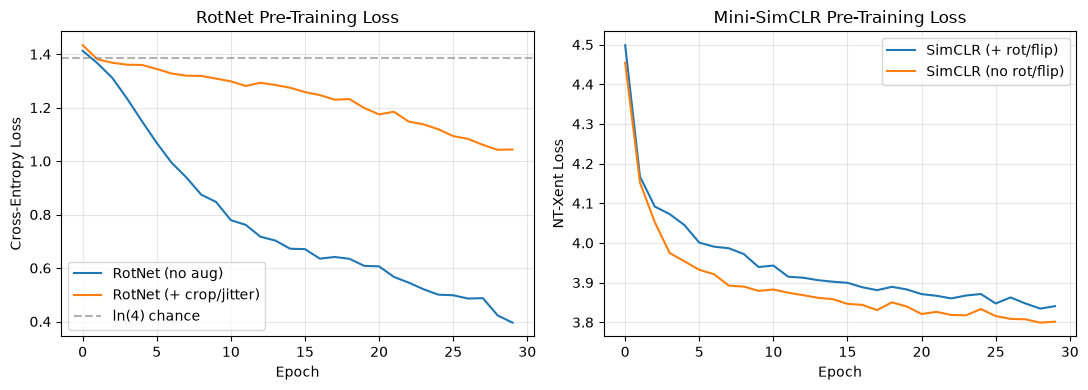

In [5]:
simclr_rot, sim_rot_losses = train_simclr(
    unlabeled_images, pcam_mean, pcam_std, epochs=30, batch_size=128, use_rotation=True, seed=42, device=device
)
simclr_norot, sim_norot_losses = train_simclr(
    unlabeled_images, pcam_mean, pcam_std, epochs=30, batch_size=128, use_rotation=False, seed=42, device=device
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(rot_raw_losses, label="RotNet (no aug)")
axes[0].plot(rot_aug_losses, label="RotNet (+ crop/jitter)")
axes[0].axhline(np.log(4), color="gray", linestyle="--", alpha=0.6, label="ln(4) chance")
axes[0].set_title("RotNet Pre-Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(sim_rot_losses, label="SimCLR (+ rot/flip)")
axes[1].plot(sim_norot_losses, label="SimCLR (no rot/flip)")
axes[1].set_title("Mini-SimCLR Pre-Training Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("NT-Xent Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Part 3 — Downstream Evaluation (Frozen Linear Probe & End-to-End Fine-Tuning)
We construct both reference baselines (`Random Init (BN-cal)` and `ImageNet (pretrained)`), then run:
- **Protocol 1:** Frozen linear probe (`StandardScaler` + 5-fold `LogisticRegressionCV`) across all 10 draws of $N_c = 100$.
- **Protocol 2:** End-to-end fine-tuning (100 epochs, Adam `lr=1e-3`, `wd=1e-3`, batch size 64) across 3 draws of $N_c = 100$.

In [6]:
set_seed(42)
random_model = BackboneWrapper(pretrained=False).to(device)
calibrate_batchnorm(random_model, unlabeled_images, pcam_mean, pcam_std, device)

imagenet_model = BackboneWrapper(pretrained=True).to(device)

model_specs = {
    "Random Init (BN-cal)": (random_model, pcam_mean, pcam_std),
    "ImageNet (pretrained)": (imagenet_model, IMAGENET_MEAN, IMAGENET_STD),
    "RotNet (no aug)": (rotnet_raw, pcam_mean, pcam_std),
    "RotNet (+ crop/jitter)": (rotnet_aug, pcam_mean, pcam_std),
    "SimCLR (no rot/flip)": (simclr_norot, pcam_mean, pcam_std),
    "SimCLR (+ rot/flip)": (simclr_rot, pcam_mean, pcam_std),
}

probe_results = evaluate_linear_probe_models(
    model_specs, labeled_seeds, test_images, test_labels, device
)

print_paired_differences(probe_results, [
    ("SimCLR (+ rot/flip)", "RotNet (no aug)"),
    ("SimCLR (+ rot/flip)", "RotNet (+ crop/jitter)"),
    ("SimCLR (+ rot/flip)", "SimCLR (no rot/flip)"),
])

plot_mean_roc_curves(probe_results, save_path="roc_curves_comparison.png")


[Protocol 1] Frozen Linear Probe (10 draws of Nc=100, 5000 test patches)...


  Random Init (BN-cal)       | Acc:  65.0 ± 2.7% | AUC: 0.708 ± 0.032


  ImageNet (pretrained)      | Acc:  75.7 ± 1.1% | AUC: 0.828 ± 0.015


  RotNet (no aug)            | Acc:  56.2 ± 5.0% | AUC: 0.546 ± 0.099


  RotNet (+ crop/jitter)     | Acc:  63.1 ± 1.8% | AUC: 0.708 ± 0.023


  SimCLR (no rot/flip)       | Acc:  76.4 ± 1.3% | AUC: 0.838 ± 0.009


  SimCLR (+ rot/flip)        | Acc:  76.0 ± 1.8% | AUC: 0.831 ± 0.019

Paired Linear-Probe Differences across identical draws (mean ± SD, ddof=1):
  SimCLR (+ rot/flip) vs RotNet (no aug): ΔAcc = +19.8 ± 4.6% | ΔAUC = +0.285 ± 0.092 (10/10 draws higher AUC)
  SimCLR (+ rot/flip) vs RotNet (+ crop/jitter): ΔAcc = +12.9 ± 2.6% | ΔAUC = +0.123 ± 0.030 (10/10 draws higher AUC)
  SimCLR (+ rot/flip) vs SimCLR (no rot/flip): ΔAcc = -0.4 ± 1.0% | ΔAUC = -0.007 ± 0.013 (3/10 draws higher AUC)



Saved mean ROC plot to: roc_curves_comparison.png


In [7]:
finetune_results = evaluate_finetune_models(
    model_specs, labeled_seeds, test_images, test_labels, device,
    finetune_seeds=FINETUNE_SEEDS, epochs=100
)

print("\n" + "=" * 98)
print(f"{'Model':<24} | {'Linear Probe Acc':<16} | {'Linear Probe AUC':<16} | {'Fine-Tune Acc':<15} | {'Fine-Tune AUC':<14}")
print("-" * 98)
for name in model_specs:
    p = probe_results[name]
    f = finetune_results[name]
    print(
        f"{name:<24} | {p['mean_acc']:5.1f} ± {p['std_acc']:4.1f}%   | "
        f"{p['mean_auc']:.3f} ± {p['std_auc']:.3f}   | "
        f"{f['mean_acc']:5.1f} ± {f['std_acc']:4.1f}%  | "
        f"{f['mean_auc']:.3f} ± {f['std_auc']:.3f}"
    )
print("=" * 98)


[Protocol 2] End-to-End Fine-Tuning (100 epochs, 3 draws of Nc=100)...


  Random Init (BN-cal)       | Acc:  64.1 ± 3.9% | AUC: 0.701 ± 0.048


  ImageNet (pretrained)      | Acc:  68.3 ± 11.1% | AUC: 0.746 ± 0.129


  RotNet (no aug)            | Acc:  63.2 ± 2.2% | AUC: 0.684 ± 0.030


  RotNet (+ crop/jitter)     | Acc:  66.4 ± 4.9% | AUC: 0.719 ± 0.067


  SimCLR (no rot/flip)       | Acc:  65.9 ± 2.0% | AUC: 0.752 ± 0.053


  SimCLR (+ rot/flip)        | Acc:  63.6 ± 1.0% | AUC: 0.692 ± 0.027

Model                    | Linear Probe Acc | Linear Probe AUC | Fine-Tune Acc   | Fine-Tune AUC 
--------------------------------------------------------------------------------------------------
Random Init (BN-cal)     |  65.0 ±  2.7%   | 0.708 ± 0.032   |  64.1 ±  3.9%  | 0.701 ± 0.048
ImageNet (pretrained)    |  75.7 ±  1.1%   | 0.828 ± 0.015   |  68.3 ± 11.1%  | 0.746 ± 0.129
RotNet (no aug)          |  56.2 ±  5.0%   | 0.546 ± 0.099   |  63.2 ±  2.2%  | 0.684 ± 0.030
RotNet (+ crop/jitter)   |  63.1 ±  1.8%   | 0.708 ± 0.023   |  66.4 ±  4.9%  | 0.719 ± 0.067
SimCLR (no rot/flip)     |  76.4 ±  1.3%   | 0.838 ± 0.009   |  65.9 ±  2.0%  | 0.752 ± 0.053
SimCLR (+ rot/flip)      |  76.0 ±  1.8%   | 0.831 ± 0.019   |  63.6 ±  1.0%  | 0.692 ± 0.027


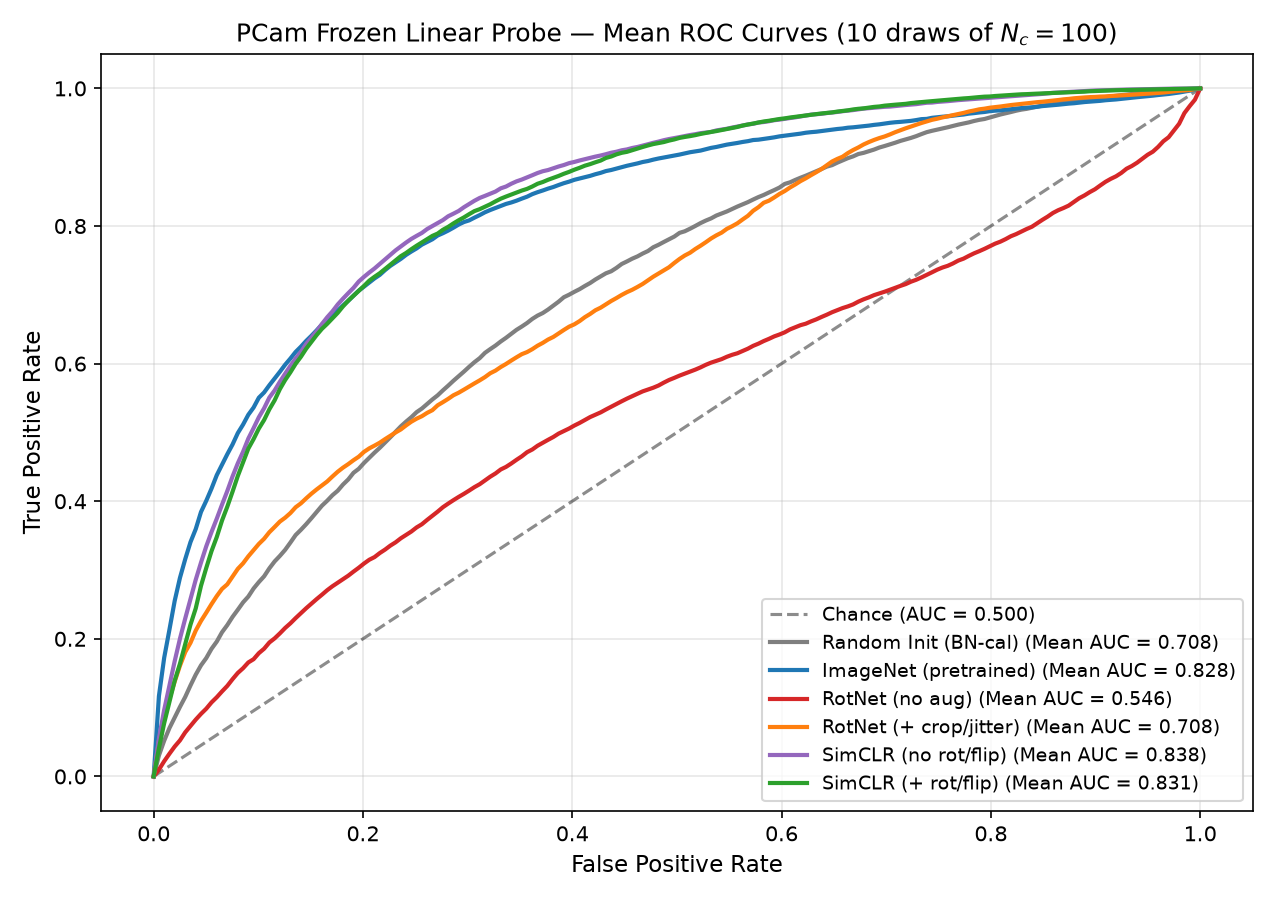

In [8]:
from IPython.display import Image as IPImage
IPImage(filename="roc_curves_comparison.png")

## 6. Limitations & Notes
- **Single SSL Pre-Training Seed:** Each SSL backbone is trained once (`seed=42`); reported standard deviations (`ddof=1`) measure sensitivity across downstream labeled draws, not SSL training variance.
- **Pre-Training Budget vs. Paper:** SSL models are trained for 30 epochs (rather than 100 in Kupferschmidt et al., MIDL 2021) on 4,000 shuffled patches.
- **Split Independence:** Official PCam `train` and `test` splits from `1aurent/PatchCamelyon` are used; slide IDs are not exposed in the dataset to independently verify patient-level separation.
- **Test Subset:** Evaluation uses a balanced, shuffled 5,000-patch subset of the 32,768-patch official test split.